# Proponer el subtipo de los dulces de leche sin subtipo (prueba)
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

Dentro del tag **DDL** hay muestras sin subtipo: no tienen descripción y no se pudieron clasificar a mano (la mayoría
son de IND-38). La idea es que el agrupamiento o un modelo predictivo les proponga uno. Este cuaderno es **de prueba** y
no cambia nada del notebook completo.

| | qué se hace |
|---|---|
| 1 | etiquetas: **familiar**, **repostero** (incluye el alfajorero, que «en teoría» es repostero) y **heladero**; las sin subtipo quedan aparte |
| 2 | tres métodos: (a) la **regla** de `prueba_ddl_repostero`; (b) la **mezcla actual** (GMM, k = 6) con su mapeo de componentes; (c) **supervisados** (regresión logística multinomial, bosque aleatorio chico; LDA de referencia) |
| 3 | validación **estratificada** (5 pliegues) y **por cliente** (se deja afuera un cliente por vez): lo que importa es acertar en clientes no vistos |
| 4 | calibración de las probabilidades; ¿ayuda la actividad de agua (Aw)? |
| 5 | ¿las sin subtipo se parecen a algún subtipo? Novedad por distancia de Mahalanobis y LOF |
| 6 | subtipo propuesto con su probabilidad y un umbral explícito; debajo del umbral, o si es novedad, queda **sin decidir** |

Métrica principal: **exactitud balanceada** (promedio de la sensibilidad de las tres clases; 1/3 = azar). Semilla 42.
Al final, el **veredicto**.

## 0 · Rutas, parámetros y funciones

In [1]:
import sys
import warnings
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.covariance import MinCovDet
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, log_loss
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import rutas as R
import mejoras_clustering as M
from datos_clase41 import COLUMNAS, SEMILLA, a_numero, leer_mq, leer_senasa

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

SALIDA = R.RESULTADOS / "prueba_subtipo_ddl"; SALIDA.mkdir(parents=True, exist_ok=True)
CLASES = ["FAMILIAR", "REPOSTERO", "HELADERO"]
COLOR = {"FAMILIAR": "#2a78d6", "REPOSTERO": "#eb6834", "HELADERO": "#1baf7a", "sin subtipo": "#b0aea5"}
TINTA, TINTA2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "font.size": 9})
# (a) la regla: heladero si la mezcla lo manda a DDL_HELADERO o si cenizas > 2,0 y humedad ≤ 26; después repostero si
# humedad ≤ 27,6 y cenizas ≤ 2,0 (prueba_ddl_repostero); el resto, familiar. Umbrales elegidos mirando la etiqueta.
REGLA = dict(hel_cenizas_min=2.0, hel_humedad_max=26.0, rep_humedad_max=27.6, rep_cenizas_max=2.0)
UMBRAL = 0.70          # probabilidad mínima para decidir un subtipo
PCT_NOVEDAD = 99       # novedad: más allá del percentil 99 de la distancia de Mahalanobis de TODAS las clases (o LOF)
CLIENTE_FOCO = "IND-38"
CV_ESTR = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
CV_CLI = LeaveOneGroupOut()
AW = "Resultado Actividad de agua (% Aw) (*)"
S = leer_senasa()
MQ, _ = leer_mq()
MQ_CLIENTE = MQ.drop_duplicates("codigo").set_index("codigo")["cliente"]
RES = {}


def cargar_ddl(v, con_mq):
    # Muestras del tag DDL de clusters_{v}.csv + subtipo de referencia, cliente (IND-nn de Senasa; si falta, el de MQ;
    # si no, «sin cliente»), Aw y si la descripción dice alfajorero. Recalcula el subtag de la mezcla (el segundo nivel anterior).
    muestras, _ = M.preparar(con_mq, S)
    cl = pd.read_csv(R.TABLAS / f"clusters_{v}.csv", encoding="utf-8-sig")
    d = cl[cl["tag"] == "DDL"].merge(muestras[["Identificador", "subtipo_ref", "fuente_subtipo"]], on="Identificador",
                                    how="left", validate="one_to_one").reset_index(drop=True)
    cr = S.crudo.set_index("Identificador")
    d["cliente"] = d["Identificador"].map(cr["Cliente"]).fillna(d["Identificador"].map(MQ_CLIENTE)).fillna("sin cliente")
    d["aw"] = a_numero(d["Identificador"].map(cr[AW]))
    texto = d["Identificador"].map(cr[["Descripción", "desc_producto", "desc_atributos", "desc_subtipo"]].astype("string")
                                   .fillna("").agg(" ".join, axis=1)).fillna("").str.upper()
    d["alfajorero"] = texto.str.contains("ALFAJOR")
    d["subtipo"] = d["subtipo_ref"].where(~d["alfajorero"], "REPOSTERO")      # alfajorero → repostero
    X = d[COLUMNAS].to_numpy()
    sub, modelos = M.subtags(X, np.array(["DDL"] * len(d), dtype=object), d["subtipo_ref"])
    # El notebook único ya no usa esta mezcla (su segundo nivel sale de segundo_nivel.py, con la logística que salió de
    # prueba_subtipo_ddl). Acá se recalcula la mezcla, que es determinista, y su subtag reemplaza al de clusters_*.csv:
    # la prueba compara contra el segundo nivel que había cuando se hizo.
    d["subtag"] = sub
    m = modelos["DDL"]
    Z = m["escalador"].transform(X)
    d["componente"] = m["gmm"].predict(Z)
    return d, m, m["gmm"].predict_proba(Z)


# ---------- los métodos: cada uno es ajustar(índices de entrenamiento) → función que da P(clase) para índices de prueba
def una_caliente(etiquetas):
    return np.array([[float(e == k) for k in CLASES] for e in etiquetas])


def metodo_regla(d):
    hel = (d["subtag"] == "DDL_HELADERO") | ((d["cenizas"] > REGLA["hel_cenizas_min"]) & (d["humedad"] <= REGLA["hel_humedad_max"]))
    rep = ~hel & (d["humedad"] <= REGLA["rep_humedad_max"]) & (d["cenizas"] <= REGLA["rep_cenizas_max"])
    P = una_caliente(np.where(hel, "HELADERO", np.where(rep, "REPOSTERO", "FAMILIAR")))
    return lambda tr: (lambda te: P[te])


def metodo_gmm_actual(d):
    # el mapeo de proponer_subtag tal cual: DDL_FAMILIAR → familiar, DDL_HELADERO → heladero, el resto → sin decidir
    # (fila de ceros: cuenta como error). Nunca propone repostero.
    P = np.zeros((len(d), 3))
    P[d["subtag"] == "DDL_FAMILIAR", 0] = 1; P[d["subtag"] == "DDL_HELADERO", 2] = 1
    return lambda tr: (lambda te: P[te])


def metodo_gmm_mapeada(d, resp, alfa=1.0):
    # la misma mezcla (ajustada sin etiquetas sobre todo el DDL), pero cada componente se mapea con las etiquetas del
    # entrenamiento: P(clase | componente) con peso de clase balanceado y suavizado alfa; P(clase | x) = Σ_k P(k | x)·P(clase | k)
    y = d["subtipo"].to_numpy()
    def ajustar(tr):
        tr = np.asarray(tr)
        Y = una_caliente(y[tr])
        frec = Y.sum(axis=0); w = (Y / np.where(frec > 0, frec, 1)).sum(axis=1)
        cuenta = resp[tr].T @ (Y * w[:, None]) + alfa * 1e-3
        p_k = cuenta / cuenta.sum(axis=1, keepdims=True)
        return lambda te: resp[te] @ p_k
    return ajustar


def metodo_sk(d, fabrica, cols=COLUMNAS):
    X = d[cols].to_numpy(); y = d["subtipo"].to_numpy()
    def ajustar(tr):
        m = fabrica().fit(X[tr], y[tr])
        orden = [list(m.classes_).index(k) for k in CLASES]
        return lambda te: m.predict_proba(X[te])[:, orden]
    return ajustar


FABRICAS = {
    "regresión logística": lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, C=1.0)),
    "bosque aleatorio": lambda: RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=10, class_weight="balanced",
                                                       random_state=SEMILLA, n_jobs=-1),
    "LDA": lambda: make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
}


def metodos(d, resp):
    out = {"(a) regla": metodo_regla(d), "(b) mezcla actual (mapeo de proponer_subtag)": metodo_gmm_actual(d),
           "(b) mezcla actual, componentes mapeados": metodo_gmm_mapeada(d, resp)}
    out |= {f"(c) {n}": metodo_sk(d, f) for n, f in FABRICAS.items()}
    return out


def fuera_de_pliegue(ajustar, idx, y, grupos, cv):
    # probabilidades fuera de pliegue para las filas idx (etiquetadas)
    P = np.full((len(idx), 3), np.nan)
    divisiones = cv.split(idx, y, grupos) if grupos is not None else cv.split(idx, y)
    for tr, te in divisiones:
        P[te] = ajustar(idx[tr])(idx[te])
    return P


def predecir(P):
    # clase con más probabilidad; fila de ceros → «sin decidir»
    return np.where(P.sum(axis=1) > 0, np.array(CLASES)[P.argmax(axis=1)], "sin decidir")


def resumen(y, P):
    pred = predecir(P); conf = P.max(axis=1)
    Pn = np.clip(P, 1e-6, 1); Pn = Pn / Pn.sum(axis=1, keepdims=True)
    Y = una_caliente(y)
    bins = np.linspace(1 / 3, 1, 8); b = np.clip(np.digitize(conf, bins) - 1, 0, len(bins) - 2)
    ece = sum(abs((pred[b == i] == y[b == i]).mean() - conf[b == i].mean()) * (b == i).mean() for i in range(len(bins) - 1) if (b == i).any())
    dec = conf >= UMBRAL
    return {"exactitud balanceada": round(balanced_accuracy_score(y, pred), 3), "exactitud": round((pred == y).mean(), 3),
            "Brier": round(((P - Y) ** 2).sum(axis=1).mean(), 3), "log loss": round(log_loss(y, Pn, labels=CLASES), 3),
            "ECE": round(ece, 3), f"% con prob ≥ {UMBRAL:.2f}": round(100 * dec.mean(), 1),
            f"exactitud balanceada con prob ≥ {UMBRAL:.2f}": round(balanced_accuracy_score(y[dec], pred[dec]), 3) if dec.sum() > 10 else np.nan}


def matriz(y, P):
    pred = predecir(P); cols = CLASES + (["sin decidir"] if (pred == "sin decidir").any() else [])
    return pd.DataFrame(confusion_matrix(y, pred, labels=cols)[:3], index=[f"real: {k.lower()}" for k in CLASES],
                        columns=[f"pred: {k.lower()}" for k in cols])


def mahalanobis_por_clase(X_lab, y_lab, X):
    # distancia de Mahalanobis robusta (MCD) a cada clase; umbral = percentil PCT_NOVEDAD de los propios miembros
    D, U = {}, {}
    for k in CLASES:
        mcd = MinCovDet(random_state=SEMILLA).fit(X_lab[y_lab == k])
        D[k] = mcd.mahalanobis(X); U[k] = np.percentile(mcd.mahalanobis(X_lab[y_lab == k]), PCT_NOVEDAD)
    D = pd.DataFrame(D)
    return D, pd.Series(U), (D > pd.Series(U)).all(axis=1).to_numpy()


def guardar(fig, nombre):
    fig.savefig(SALIDA / nombre, dpi=150, bbox_inches="tight", facecolor="white")
    print("PNG:", (SALIDA / nombre).relative_to(R.RAIZ))

## 1 · Solo Senasa
### 1.1 · Etiquetas y clientes
Las muestras con tag DDL de `resultados/tablas/clusters_senasa.csv` (con los outliers, que también llevan tag). Etiqueta =
subtipo de referencia; el alfajorero pasa a repostero. ¿Cuántas sin subtipo hay por cliente y cuántas etiquetadas tiene
cada uno? En particular, **¿IND-38 tiene muestras etiquetadas?**

In [2]:
v = "senasa"
d, modelo, resp = cargar_ddl(v, False)
lab = d["subtipo"].notna().to_numpy(); idx = np.flatnonzero(lab)
y = d.loc[lab, "subtipo"].to_numpy(); g = d.loc[lab, "cliente"].to_numpy()
print(f"{len(d)} muestras DDL · {lab.sum()} etiquetadas · {(~lab).sum()} sin subtipo · mezcla k = {modelo['k_bic']} · subtag de la mezcla recalculado")
print("Alfajoreros (por texto):", int(d["alfajorero"].sum()), "· su subtipo de referencia:", d.loc[d["alfajorero"], "subtipo_ref"].value_counts(dropna=False).to_dict())
display(d["subtipo"].fillna("sin subtipo").value_counts().to_frame("muestras").T)
t = pd.crosstab(d["cliente"], d["subtipo"].fillna("sin subtipo")).reindex(columns=CLASES + ["sin subtipo"], fill_value=0)
t["etiquetadas"] = t[CLASES].sum(axis=1)
print(f"Clientes con al menos 5 sin subtipo ({d.loc[~lab, 'cliente'].nunique()} clientes tienen alguna):")
display(t[t["sin subtipo"] >= 5].sort_values("sin subtipo", ascending=False))
print(f"Clientes con etiquetadas: {(t['etiquetadas'] > 0).sum()} (son los grupos de la validación por cliente)")
foco = d[d["cliente"] == CLIENTE_FOCO]
print(f"{CLIENTE_FOCO}: {len(foco)} muestras, {foco['subtipo'].notna().sum()} etiquetadas:", foco["subtipo"].value_counts().to_dict())

2116 muestras DDL · 1521 etiquetadas · 595 sin subtipo · mezcla k = 6 · subtag de la mezcla recalculado
Alfajoreros (por texto): 27 · su subtipo de referencia: {'REPOSTERO': 27}


subtipo,FAMILIAR,REPOSTERO,sin subtipo,HELADERO
muestras,749,620,595,152


Clientes con al menos 5 sin subtipo (21 clientes tienen alguna):


subtipo,FAMILIAR,REPOSTERO,HELADERO,sin subtipo,etiquetadas
cliente,,,,,
IND-38,4,13,0,326,17
IND-67,0,9,0,89,9
IND-11,136,52,0,61,188
IND-25,1,2,0,60,3
IND-107,4,29,0,12,33
IND-51,567,459,140,11,1166
IND-104,0,2,0,5,2
IND-52,15,12,2,5,29
IND-99,4,4,2,5,10


Clientes con etiquetadas: 24 (son los grupos de la validación por cliente)
IND-38: 343 muestras, 17 etiquetadas: {'REPOSTERO': 13, 'FAMILIAR': 4}


### 1.2 · Los métodos, con validación estratificada y por cliente
Para cada método, probabilidades **fuera de pliegue** sobre las etiquetadas: (i) estratificada en 5 pliegues; (ii) por
cliente, dejando afuera un cliente por vez (`LeaveOneGroupOut`; las muestras sin cliente forman un grupo). La regla y el
mapeo de `proponer_subtag` no se reajustan en cada pliegue (sus umbrales y su mapeo se fijaron con todas las etiquetas),
así que su validación es **optimista**. La mezcla con componentes mapeados usa la mezcla actual (que se ajustó sin
etiquetas) y aprende P(clase | componente) solo con el entrenamiento de cada pliegue. «Sin decidir» cuenta como error.
Brier y log loss: menor es mejor. ECE: diferencia media entre la confianza y el acierto.

In [3]:
MET = metodos(d, resp)
OOF = {"estratificada": {}, "por cliente": {}}
filas = []
for nombre, ajustar in MET.items():
    for val, cv, gr in [("estratificada", CV_ESTR, None), ("por cliente", CV_CLI, g)]:
        P = fuera_de_pliegue(ajustar, idx, y, gr, cv); OOF[val][nombre] = P
        filas.append({"método": nombre, "validación": val} | resumen(y, P))
tabla = pd.DataFrame(filas).set_index(["método", "validación"])
display(tabla)
ba = tabla["exactitud balanceada"].unstack()[["estratificada", "por cliente"]]
print("Exactitud balanceada, método × validación:"); display(ba)
probabilisticos = [n for n in MET if "(c)" in n or "mapeados" in n]
# criterio explícito: entre los métodos con probabilidades a menos de 0,01 de la mejor exactitud balanceada por cliente,
# el de menor Brier (las probabilidades se usan con un umbral, así que importa que estén calibradas)
pc = tabla.xs("por cliente", level="validación").loc[probabilisticos]
empatados = pc[pc["exactitud balanceada"] >= pc["exactitud balanceada"].max() - 0.01]
mejor = empatados["Brier"].idxmin()
print("Empatados (a menos de 0,01 de la mejor exactitud balanceada por cliente):", empatados.index.tolist())
print("Mejor método con probabilidades según la validación por cliente (menor Brier entre los empatados):", mejor)
for val in ["estratificada", "por cliente"]:
    print(f"Matriz de confusión del mejor ({val}):"); display(matriz(y, OOF[val][mejor]))
print("Matriz de confusión de la regla (por cliente):"); display(matriz(y, OOF["por cliente"]["(a) regla"]))
print("Matriz de confusión de la mezcla actual (mapeo de proponer_subtag):"); display(matriz(y, OOF["por cliente"]["(b) mezcla actual (mapeo de proponer_subtag)"]))

exactitud balanceada  exactitud  Brier  log loss    ECE  % con prob ≥ 0.70  exactitud balanceada con prob ≥ 0.70
método                                       validación                                                                                                                     
(a) regla                                    estratificada                 0.835      0.836  0.327     7.739  0.164              100.0                                 0.835
                                             por cliente                   0.835      0.836  0.327     7.739  0.164              100.0                                 0.835
(b) mezcla actual (mapeo de proponer_subtag) estratificada                 0.525      0.464  0.581     2.257  0.045               50.8                                 0.667
                                             por cliente                   0.525      0.464  0.581     2.257  0.045               50.8                                 0.667
(b) mezcla actual, componentes mapeados      estratificada                 0.822      0.817  0.264     2.233  0.049               76.9                                 0.926
                                             por cliente                   0.746      0.694  0.409     1.811  0.185               19.7                                 0.695
(c) regresión logística                      estratificada                 0.902      0.880  0.191     3.707  0.034               82.7                                 0.937
                                             por cliente                   0.862      0.835  0.259     3.730  0.082               69.7                                 0.911
(c) bosque aleatorio                         estratificada                 0.906      0.884  0.173     2.768  0.044               83.5                                 0.950
                                             por cliente                   0.863      0.855  0.295     1.857  0.168               53.5                                 0.885
(c) LDA                                      estratificada                 0.866      0.867  0.202     6.944  0.044               80.8                                 0.916
                                             por cliente                   0.830      0.811  0.284     6.770  0.080               65.0                                 0.892

Exactitud balanceada, método × validación:


validación,estratificada,por cliente
método,,
(a) regla,0.835,0.835
(b) mezcla actual (mapeo de proponer_subtag),0.525,0.525
"(b) mezcla actual, componentes mapeados",0.822,0.746
(c) LDA,0.866,0.830
(c) bosque aleatorio,0.906,0.863
(c) regresión logística,0.902,0.862


Empatados (a menos de 0,01 de la mejor exactitud balanceada por cliente): ['(c) regresión logística', '(c) bosque aleatorio']
Mejor método con probabilidades según la validación por cliente (menor Brier entre los empatados): (c) regresión logística
Matriz de confusión del mejor (estratificada):


,pred: familiar,pred: repostero,pred: heladero
real: familiar,656,91,2
real: repostero,79,536,5
real: heladero,2,3,147


Matriz de confusión del mejor (por cliente):


,pred: familiar,pred: repostero,pred: heladero
real: familiar,653,94,2
real: repostero,138,472,10
real: heladero,0,7,145


Matriz de confusión de la regla (por cliente):


,pred: familiar,pred: repostero,pred: heladero
real: familiar,655,93,1
real: repostero,127,489,4
real: heladero,14,10,128


Matriz de confusión de la mezcla actual (mapeo de proponer_subtag):


,pred: familiar,pred: repostero,pred: heladero,pred: sin decidir
real: familiar,584,0,0,165
real: repostero,68,0,0,552
real: heladero,0,0,121,31


### 1.3 · Por cliente: ¿dónde acierta y dónde no?
Exactitud (no balanceada: dentro de un cliente puede faltar alguna clase) de la validación por cliente en los clientes con
al menos 15 etiquetadas, y en {CLIENTE_FOCO}. Para IND-38, las pocas etiquetadas que tiene son la **única estimación
directa** de cómo le va al modelo con ese cliente.

In [4]:
filas = []
clientes = [c_ for c_, n_ in pd.Series(g).value_counts().items() if n_ >= 15 or c_ == CLIENTE_FOCO]
for c_ in clientes:
    s_ = g == c_
    f_ = {"cliente": c_, "etiquetadas": int(s_.sum())} | {k.lower(): int((y[s_] == k).sum()) for k in CLASES}
    for n_ in ["(a) regla", "(b) mezcla actual, componentes mapeados", "(c) regresión logística", "(c) bosque aleatorio", "(c) LDA"]:
        f_[n_] = round((predecir(OOF["por cliente"][n_][s_]) == y[s_]).mean(), 2)
    filas.append(f_)
por_cliente = pd.DataFrame(filas).set_index("cliente"); display(por_cliente)
s_ = g == CLIENTE_FOCO
if s_.any():
    q_ = d.loc[idx[s_], ["Identificador", "subtipo"] + COLUMNAS].copy()
    q_["predicho (mejor, por cliente)"] = predecir(OOF["por cliente"][mejor][s_]); q_["prob."] = OOF["por cliente"][mejor][s_].max(axis=1).round(2)
    print(f"Las etiquetadas de {CLIENTE_FOCO}, predichas sin haber visto a {CLIENTE_FOCO}:"); display(q_.round(2))

,etiquetadas,familiar,repostero,heladero,(a) regla,"(b) mezcla actual, componentes mapeados",(c) regresión logística,(c) bosque aleatorio,(c) LDA
cliente,,,,,,,,,
IND-51,1166,567,459,140,0.89,0.74,0.89,0.91,0.86
IND-11,188,136,52,0,0.61,0.70,0.56,0.64,0.56
IND-107,33,4,29,0,0.76,0.03,0.64,0.67,0.61
IND-52,29,15,12,2,0.83,0.41,0.86,0.79,0.83
IND-71,20,3,17,0,0.90,0.05,0.65,0.75,0.80
IND-38,17,4,13,0,0.35,0.76,1.00,0.12,1.00


Las etiquetadas de IND-38, predichas sin haber visto a IND-38:


,Identificador,subtipo,humedad,grasa,proteinas,cenizas,"predicho (mejor, por cliente)",prob.
43,MQ-14387-02,REPOSTERO,26.62,8.88,10.03,2.51,REPOSTERO,0.75
44,MQ-14387-03,REPOSTERO,27.28,8.80,9.73,2.48,REPOSTERO,0.74
58,MQ-14551-02,REPOSTERO,27.61,8.79,9.74,2.33,REPOSTERO,0.97
59,MQ-14587-01,REPOSTERO,25.29,6.85,8.89,2.20,REPOSTERO,0.83
60,MQ-14587-02,REPOSTERO,25.74,7.40,8.14,2.00,REPOSTERO,0.92
63,MQ-14711-02,REPOSTERO,26.38,8.85,9.85,2.40,REPOSTERO,0.89
66,MQ-14807-01,REPOSTERO,25.33,6.89,8.88,1.99,REPOSTERO,0.99
68,MQ-14876-02,REPOSTERO,26.66,8.77,10.49,2.41,REPOSTERO,0.99
77,MQ-14951-01,FAMILIAR,30.19,7.71,7.21,1.63,FAMILIAR,0.92
83,MQ-15005-01,REPOSTERO,25.40,6.96,9.21,2.28,REPOSTERO,0.81


### 1.4 · Calibración y umbral
Diagrama de confiabilidad (validación por cliente): confianza (probabilidad de la clase elegida) contra el acierto real,
en tramos. Debajo, para el mejor método, la exactitud balanceada y el porcentaje de muestras decididas según el umbral.

PNG: resultados\prueba_subtipo_ddl\calibracion_senasa.png


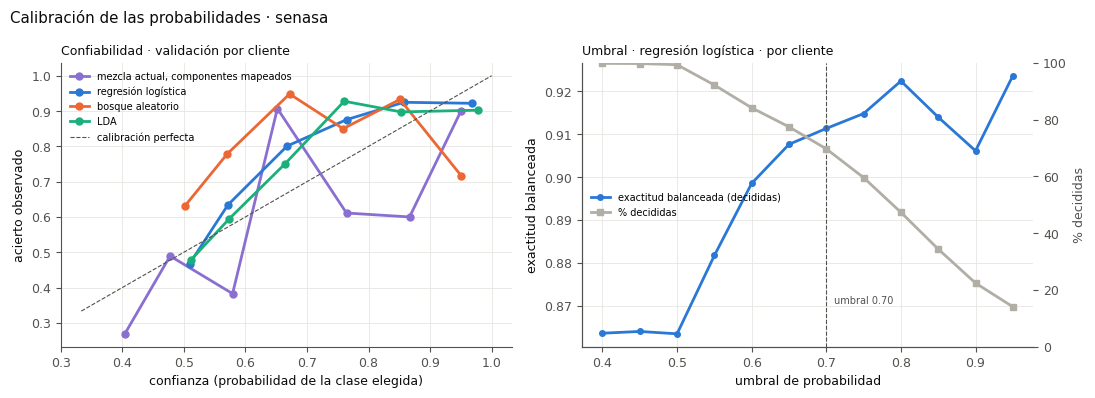

umbral,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95
% decididas,99.803,99.737,99.343,92.176,84.155,77.449,69.691,59.566,47.337,34.385,22.419,14.070
exactitud balanceada,0.864,0.864,0.863,0.882,0.899,0.908,0.911,0.915,0.922,0.914,0.906,0.924


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.0))
ax = axs[0]
bins = np.linspace(1 / 3, 1, 8)
estilo = {"(b) mezcla actual, componentes mapeados": "#8a6fd1", "(c) regresión logística": "#2a78d6", "(c) bosque aleatorio": "#eb6834", "(c) LDA": "#1baf7a"}
for n_, col_ in estilo.items():
    P = OOF["por cliente"][n_]; conf = P.max(axis=1); ok = predecir(P) == y
    b = np.clip(np.digitize(conf, bins) - 1, 0, len(bins) - 2)
    xs = [conf[b == i].mean() for i in range(len(bins) - 1) if (b == i).sum() >= 10]
    ys = [ok[b == i].mean() for i in range(len(bins) - 1) if (b == i).sum() >= 10]
    ax.plot(xs, ys, marker="o", ms=5, lw=2, color=col_, label=n_.replace("(b) ", "").replace("(c) ", ""))
ax.plot([1 / 3, 1], [1 / 3, 1], color=TINTA2, lw=0.8, ls="--", label="calibración perfecta")
ax.set_xlabel("confianza (probabilidad de la clase elegida)"); ax.set_ylabel("acierto observado")
ax.set_title("Confiabilidad · validación por cliente", loc="left", fontsize=9, color=TINTA); ax.legend(fontsize=7, frameon=False, loc="upper left")
ax = axs[1]
umbrales = np.round(np.arange(0.40, 0.96, 0.05), 2); P = OOF["por cliente"][mejor]; conf = P.max(axis=1); pred = predecir(P)
curva = pd.DataFrame([{"umbral": u, "% decididas": 100 * (conf >= u).mean(),
                       "exactitud balanceada": balanced_accuracy_score(y[conf >= u], pred[conf >= u]) if (conf >= u).sum() > 10 else np.nan}
                      for u in umbrales]).set_index("umbral")
ax.plot(curva.index, curva["exactitud balanceada"], marker="o", ms=4, lw=2, color="#2a78d6", label="exactitud balanceada (decididas)")
ax2 = ax.twinx(); ax2.set_ylim(0, 100); ax2.set_ylabel("% decididas", color=TINTA2); ax2.spines["top"].set_visible(False); ax2.grid(False)
ax2.plot(curva.index, curva["% decididas"], marker="s", ms=4, lw=2, color="#b0aea5", label="% decididas")
ax.axvline(UMBRAL, color=TINTA2, lw=0.8, ls="--"); ax.text(UMBRAL + 0.01, ax.get_ylim()[0] + 0.01, f"umbral {UMBRAL:.2f}", fontsize=7, color=TINTA2)
ax.set_xlabel("umbral de probabilidad"); ax.set_ylabel("exactitud balanceada")
ax.set_title(f"Umbral · {mejor.replace('(c) ', '')} · por cliente", loc="left", fontsize=9, color=TINTA)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=7, frameon=False, loc="center left")
fig.suptitle(f"Calibración de las probabilidades · {v}", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); guardar(fig, f"calibracion_{v}.png"); plt.show()
display(curva.round(3).T)

### 1.5 · ¿Ayuda la actividad de agua (Aw)?
Solo una parte de las etiquetadas tiene Aw, casi todas familiar o repostero, así que se mira **repostero contra
familiar** con regresión logística, con y sin Aw, sobre esas mismas muestras. No se imputa: con tan pocas muestras con
valor, imputar la mediana inventaría casi toda la columna.

In [6]:
con_aw = d[lab & d["aw"].notna() & d["subtipo"].isin(["FAMILIAR", "REPOSTERO"])]
print(f"Con Aw: {d['aw'].notna().sum()} muestras DDL ({d.loc[lab, 'aw'].notna().sum()} etiquetadas, {d.loc[~lab, 'aw'].notna().sum()} sin subtipo); "
      f"familiar/repostero con Aw: {len(con_aw)}, por cliente: {con_aw['cliente'].value_counts().to_dict()}")
yy = (con_aw["subtipo"] == "REPOSTERO").astype(int).to_numpy(); gg = con_aw["cliente"].to_numpy()
fab = lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
filas = []
for nombre_, cols_ in [("4 análisis", COLUMNAS), ("4 análisis + Aw", COLUMNAS + ["aw"]), ("solo Aw", ["aw"])]:
    Xa = con_aw[cols_].to_numpy(); f_ = {"variables": nombre_}
    for val, cv in [("estratificada", CV_ESTR), ("por cliente", CV_CLI)]:
        pr = np.zeros(len(yy))
        for tr, te in (cv.split(Xa, yy, gg) if val == "por cliente" else cv.split(Xa, yy)):
            if len(np.unique(yy[tr])) < 2:
                pr[te] = yy[tr][0]; continue
            pr[te] = fab().fit(Xa[tr], yy[tr]).predict(Xa[te])
        f_[f"exactitud balanceada ({val})"] = round(balanced_accuracy_score(yy, pr), 3)
    filas.append(f_)
display(pd.DataFrame(filas).set_index("variables"))
display(con_aw.groupby(["cliente", "subtipo"])["aw"].agg(["count", "median"]).round(3))

Con Aw: 321 muestras DDL (311 etiquetadas, 10 sin subtipo); familiar/repostero con Aw: 309, por cliente: {'IND-51': 165, 'IND-11': 116, 'IND-52': 12, 'IND-71': 6, 'IND-93': 6, 'IND-41': 1, 'IND-05': 1, 'IND-107': 1, 'IND-105': 1}


,exactitud balanceada (estratificada),exactitud balanceada (por cliente)
variables,,
4 análisis,0.862,0.600
4 análisis + Aw,0.882,0.772
solo Aw,0.884,0.887


count  median
cliente subtipo                 
IND-05  REPOSTERO      1   0.751
IND-105 REPOSTERO      1   0.741
IND-107 REPOSTERO      1   0.779
IND-11  FAMILIAR      75   0.837
        REPOSTERO     41   0.839
IND-41  REPOSTERO      1   0.751
IND-51  FAMILIAR       1   0.824
        REPOSTERO    164   0.802
IND-52  FAMILIAR      10   0.828
        REPOSTERO      2   0.790
IND-71  REPOSTERO      6   0.750
IND-93  FAMILIAR       3   0.843
        REPOSTERO      3   0.812

### 1.6 · ¿Las sin subtipo se parecen a algún subtipo?
Medianas de las sin subtipo (todas y las de IND-38) junto a las de cada subtipo. Novedad: (i) distancia de **Mahalanobis
robusta** (MCD) a cada clase; una muestra es novedad si queda más allá del percentil {PCT} de los propios miembros en
**las tres** clases; (ii) **LOF** en modo novedad (30 vecinos, ajustado con las etiquetadas estandarizadas), con el corte en el percentil 1 del
puntaje de las etiquetadas (calculado fuera de pliegue); el corte por defecto de LOF daba entre 8 y 31 % de falsas
alarmas. Se marca como novedad si lo dice cualquiera de los dos. Como referencia, la tasa de falsas alarmas en las etiquetadas (con LOF en
validación cruzada, para no evaluarlo sobre sus propios datos de ajuste).

In [7]:
X = d[COLUMNAS].to_numpy(); Xl = X[lab]
grupo = np.where(lab, d["subtipo"].fillna(""), np.where(d["cliente"] == CLIENTE_FOCO, "sin subtipo · IND-38", "sin subtipo · otros"))
med = pd.DataFrame(X, columns=COLUMNAS).groupby(grupo).median().round(2)
med.insert(0, "muestras", pd.Series(grupo).value_counts())
display(med.loc[CLASES + ["sin subtipo · IND-38", "sin subtipo · otros"]])

D, U, nov_maha = mahalanobis_por_clase(Xl, y, X)
esc = StandardScaler().fit(Xl)
lof = LocalOutlierFactor(n_neighbors=30, novelty=True).fit(esc.transform(Xl))
puntaje = lof.score_samples(esc.transform(X))     # más bajo = más raro
oof_lof = np.zeros(lab.sum())                     # LOF en las etiquetadas, fuera de pliegue (no sobre sus datos de ajuste)
for tr, te in CV_ESTR.split(Xl, y):
    e_ = StandardScaler().fit(Xl[tr]); oof_lof[te] = LocalOutlierFactor(n_neighbors=30, novelty=True).fit(e_.transform(Xl[tr])).score_samples(e_.transform(Xl[te]))
corte_lof = np.percentile(oof_lof, 100 - PCT_NOVEDAD)   # calibrado: ~1 % de falsas alarmas en las etiquetadas
puntaje[lab] = oof_lof
nov_lof = puntaje < corte_lof
print(f"Corte de LOF (percentil {100 - PCT_NOVEDAD} del puntaje fuera de pliegue de las etiquetadas): {corte_lof:.2f}")
novedad = nov_maha | nov_lof
d["novedad"] = novedad; d["clase_mas_cercana"] = D.div(U).idxmin(axis=1)
print("Umbral de Mahalanobis por clase (percentil 99 de sus miembros):", U.round(2).to_dict())
fr = pd.DataFrame({"Mahalanobis": nov_maha, "LOF": nov_lof, "cualquiera": novedad}).groupby(grupo).mean().mul(100).round(1)
fr.insert(0, "muestras", pd.Series(grupo).value_counts())
print("% marcadas como novedad por grupo (en las etiquetadas = falsas alarmas):"); display(fr)
print("Sin subtipo: clase más cercana (Mahalanobis relativa al umbral) × novedad:")
display(pd.crosstab([pd.Series(grupo[~lab], name="grupo"), d.loc[~lab, "clase_mas_cercana"].rename("más cercana")], d.loc[~lab, "novedad"].rename("novedad")))

,muestras,humedad,grasa,proteinas,cenizas
FAMILIAR,749,28.70,6.75,5.84,1.36
REPOSTERO,620,26.64,6.84,6.63,1.50
HELADERO,152,21.76,7.02,6.73,2.56
sin subtipo · IND-38,326,29.35,8.18,7.97,1.85
sin subtipo · otros,269,28.35,6.70,6.06,1.47


Corte de LOF (percentil 1 del puntaje fuera de pliegue de las etiquetadas): -2.60
Umbral de Mahalanobis por clase (percentil 99 de sus miembros): {'FAMILIAR': 70.05, 'REPOSTERO': 65.9, 'HELADERO': 242.51}
% marcadas como novedad por grupo (en las etiquetadas = falsas alarmas):


,muestras,Mahalanobis,LOF,cualquiera
FAMILIAR,749,0.4,0.9,1.1
HELADERO,152,1.3,3.9,3.9
REPOSTERO,620,0.2,0.5,0.6
sin subtipo · IND-38,326,2.1,2.1,3.7
sin subtipo · otros,269,1.9,1.9,2.6


Sin subtipo: clase más cercana (Mahalanobis relativa al umbral) × novedad:


novedad                           False  True 
grupo                más cercana              
sin subtipo · IND-38 FAMILIAR        67      1
                     HELADERO         3      2
                     REPOSTERO      130      9
sin subtipo · otros  FAMILIAR        67      0
                     HELADERO         0      1
                     REPOSTERO       84      1

### 1.7 · Subtipo propuesto
El mejor método con probabilidades según la validación por cliente (entre los que quedan a menos de 0,01 de la mejor
exactitud balanceada, el de menor Brier) se reajusta con **todas** las etiquetadas y se aplica
a las sin subtipo. Regla de decisión explícita: si la probabilidad de la clase elegida es menor que **{UMBRAL}**, o si
la muestra es novedad, queda **sin decidir**. Las etiquetadas llevan su predicción **fuera de pliegue por cliente**
(honesta), para poder comparar con el subtipo real. Se compara además con la regla y con la mezcla actual.

In [8]:
modelo_final = MET[mejor](idx)
P_todo = modelo_final(np.arange(len(d)))
P_todo[lab] = OOF["por cliente"][mejor]
prob = P_todo.max(axis=1); pred = predecir(P_todo)
decidido = (prob >= UMBRAL) & ~novedad
d["subtipo_propuesto"] = np.where(decidido, pred, "sin decidir"); d["prob"] = prob
for k, col_ in zip(CLASES, ["p_familiar", "p_repostero", "p_heladero"]):
    d[col_] = P_todo[:, CLASES.index(k)]

sin = d[~lab]
orden = CLASES + ["sin decidir"]
conteo = pd.DataFrame({"todas las sin subtipo": sin["subtipo_propuesto"].value_counts(),
                       f"{CLIENTE_FOCO} sin subtipo": sin.loc[sin["cliente"] == CLIENTE_FOCO, "subtipo_propuesto"].value_counts(),
                       "otros clientes sin subtipo": sin.loc[sin["cliente"] != CLIENTE_FOCO, "subtipo_propuesto"].value_counts()}).reindex(orden).fillna(0).astype(int)
conteo.loc["total"] = conteo.sum(); display(conteo)
print("Por qué quedan sin decidir (sin subtipo):",
      {"novedad": int(sin["novedad"].sum()), f"prob < {UMBRAL}": int(((sin["prob"] < UMBRAL) & ~sin["novedad"]).sum())})
print("Clase más probable de las sin decidir, sin mirar el umbral:", pd.Series(pred[~lab][~decidido[~lab]]).value_counts().to_dict())
regla_sin = predecir(MET["(a) regla"](idx)(np.flatnonzero(~lab)))
print("Sin subtipo: propuesto (mejor método) × regla:"); display(pd.crosstab(sin["subtipo_propuesto"].rename("propuesto"), pd.Series(regla_sin, index=sin.index, name="regla")))
print("Sin subtipo: propuesto × subtag actual:"); display(pd.crosstab(sin["subtipo_propuesto"].rename("propuesto"), sin["subtag"]))
print("Etiquetadas (fuera de pliegue por cliente), solo las decididas: propuesto × real")
display(pd.crosstab(d.loc[lab, "subtipo"].rename("real"), d.loc[lab, "subtipo_propuesto"].rename("propuesto")))
dl = d[lab & decidido]
print(f"Etiquetadas decididas: {len(dl)} de {lab.sum()} · exactitud balanceada {balanced_accuracy_score(dl['subtipo'], dl['subtipo_propuesto']):.3f}")

out = d[["Identificador", "cliente", "origen"] + COLUMNAS + ["aw", "subtag", "componente", "subtipo", "subtipo_propuesto", "prob",
        "p_familiar", "p_repostero", "p_heladero", "novedad", "clase_mas_cercana"]].copy()
out = out.rename(columns={"subtipo": "subtipo_real", "prob": "probabilidad"})
out.insert(out.columns.get_loc("subtipo_propuesto") + 1, "metodo", mejor.replace("(c) ", "") + (" (fuera de pliegue por cliente)"))
out.loc[out["subtipo_real"].isna(), "metodo"] = mejor.replace("(c) ", "") + " (ajustado con todas las etiquetadas)"
out["decidido"] = np.where(decidido, "sí", "no"); out["umbral"] = UMBRAL
out = out.round({c_: 3 for c_ in COLUMNAS + ["aw", "probabilidad", "p_familiar", "p_repostero", "p_heladero"]})
out.to_csv(SALIDA / f"subtipo_propuesto_{v}.csv", index=False, encoding="utf-8-sig")
print("CSV:", (SALIDA / f"subtipo_propuesto_{v}.csv").relative_to(R.RAIZ), out.shape)
RES[v] = dict(ba=ba, tabla=tabla, mejor=mejor, conteo=conteo, por_cliente=por_cliente, fr=fr, d=d)

,todas las sin subtipo,IND-38 sin subtipo,otros clientes sin subtipo
subtipo_propuesto,,,
FAMILIAR,246,136,110
REPOSTERO,130,89,41
HELADERO,7,2,5
sin decidir,212,99,113
total,595,326,269


Por qué quedan sin decidir (sin subtipo): {'novedad': 19, 'prob < 0.7': 193}
Clase más probable de las sin decidir, sin mirar el umbral: {'FAMILIAR': 117, 'REPOSTERO': 91, 'HELADERO': 4}
Sin subtipo: propuesto (mejor método) × regla:


regla,FAMILIAR,HELADERO,REPOSTERO
propuesto,,,
FAMILIAR,244,0,2
HELADERO,2,2,3
REPOSTERO,81,2,47
sin decidir,184,2,26


Sin subtipo: propuesto × subtag actual:


subtag,DDL,DDL_FAMILIAR
propuesto,,
FAMILIAR,127,119
HELADERO,7,0
REPOSTERO,118,12
sin decidir,164,48


Etiquetadas (fuera de pliegue por cliente), solo las decididas: propuesto × real


propuesto,FAMILIAR,HELADERO,REPOSTERO,sin decidir
real,,,,
FAMILIAR,536,1,38,174
HELADERO,0,138,5,9
REPOSTERO,50,4,274,292


Etiquetadas decididas: 1046 de 1521 · exactitud balanceada 0.911
CSV: resultados\prueba_subtipo_ddl\subtipo_propuesto_senasa.csv (2116, 21)


### 1.8 · Gráfico: dónde caen las sin subtipo
Fondo: las etiquetadas por subtipo. Encima, las sin subtipo con el subtipo propuesto (relleno) o sin decidir (gris);
las novedades, con una cruz. Los paneles de abajo son solo IND-38.

PNG: resultados\prueba_subtipo_ddl\sin_subtipo_senasa.png


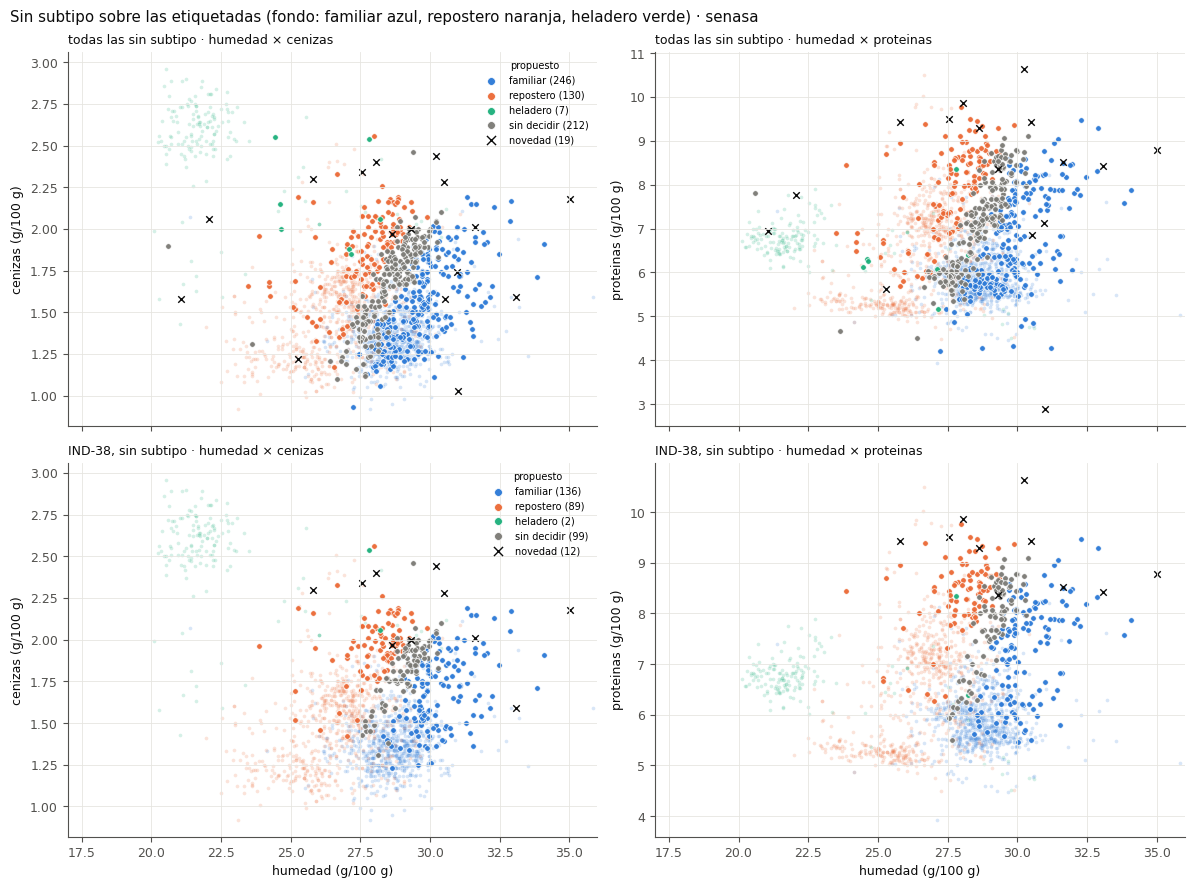

PNG: resultados\prueba_subtipo_ddl\confusion_senasa.png


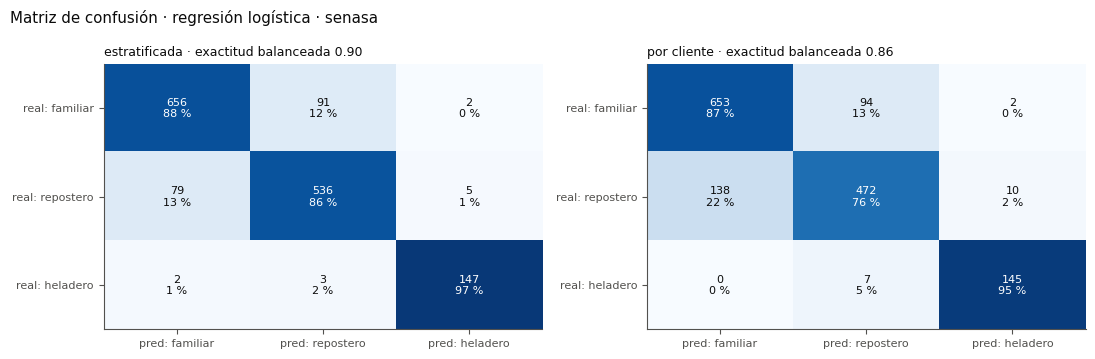

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(12, 9), sharex=True)
for fila_, sel_, rot_ in [(0, ~lab, "todas las sin subtipo"), (1, ~lab & (d["cliente"] == CLIENTE_FOCO).to_numpy(), f"{CLIENTE_FOCO}, sin subtipo")]:
    for ax, yv in zip(axs[fila_], ["cenizas", "proteinas"]):
        for k in CLASES:
            q = d[lab & (d["subtipo"] == k).to_numpy()]
            ax.scatter(q["humedad"], q[yv], s=7, color=COLOR[k], alpha=0.18, lw=0)
        s_ = d[sel_]
        for k in CLASES + ["sin decidir"]:
            q = s_[(s_["subtipo_propuesto"] == k) & ~s_["novedad"]]
            ax.scatter(q["humedad"], q[yv], s=16, color=COLOR.get(k, "#7a7974"), edgecolors="white", lw=0.5, alpha=0.95,
                       label=f"{k.lower()} ({(s_['subtipo_propuesto'] == k).sum()})")
        q = s_[s_["novedad"]]
        ax.scatter(q["humedad"], q[yv], s=22, marker="x", color=TINTA, lw=1, label=f"novedad ({len(q)})")
        ax.set_xlim(17, 36); ax.set_ylabel(f"{yv} (g/100 g)")
        ax.set_title(f"{rot_} · humedad × {yv}", loc="left", fontsize=9, color=TINTA)
        if fila_ == 1:
            ax.set_xlabel("humedad (g/100 g)")
    axs[fila_][0].legend(fontsize=7, frameon=False, markerscale=1.4, loc="upper right", title="propuesto", title_fontsize=7)
fig.suptitle(f"Sin subtipo sobre las etiquetadas (fondo: familiar azul, repostero naranja, heladero verde) · {v}", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); guardar(fig, f"sin_subtipo_{v}.png"); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, val in zip(axs, ["estratificada", "por cliente"]):
    m_ = matriz(y, OOF[val][mejor]); filas_ = m_.div(m_.sum(axis=1), axis=0)
    ax.imshow(filas_.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(m_.shape[0]):
        for j in range(m_.shape[1]):
            ax.text(j, i, f"{m_.iat[i, j]}\n{100 * filas_.iat[i, j]:.0f} %", ha="center", va="center", fontsize=8,
                    color="white" if filas_.iat[i, j] > 0.55 else TINTA)
    ax.set_xticks(range(m_.shape[1])); ax.set_xticklabels(m_.columns, fontsize=8); ax.set_yticks(range(3)); ax.set_yticklabels(m_.index, fontsize=8)
    ax.grid(False); ax.set_title(f"{val} · exactitud balanceada {balanced_accuracy_score(y, predecir(OOF[val][mejor])):.2f}", loc="left", fontsize=9, color=TINTA)
fig.suptitle(f"Matriz de confusión · {mejor.replace('(c) ', '')} · {v}", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); guardar(fig, f"confusion_{v}.png"); plt.show()

## 2 · Senasa + MQ
### 2.1 · Etiquetas y clientes
Las muestras con tag DDL de `resultados/tablas/clusters_senasa_mq.csv` (con los outliers, que también llevan tag). Etiqueta =
subtipo de referencia; el alfajorero pasa a repostero. ¿Cuántas sin subtipo hay por cliente y cuántas etiquetadas tiene
cada uno? En particular, **¿IND-38 tiene muestras etiquetadas?**

In [10]:
v = "senasa_mq"
d, modelo, resp = cargar_ddl(v, True)
lab = d["subtipo"].notna().to_numpy(); idx = np.flatnonzero(lab)
y = d.loc[lab, "subtipo"].to_numpy(); g = d.loc[lab, "cliente"].to_numpy()
print(f"{len(d)} muestras DDL · {lab.sum()} etiquetadas · {(~lab).sum()} sin subtipo · mezcla k = {modelo['k_bic']} · subtag de la mezcla recalculado")
print("Alfajoreros (por texto):", int(d["alfajorero"].sum()), "· su subtipo de referencia:", d.loc[d["alfajorero"], "subtipo_ref"].value_counts(dropna=False).to_dict())
display(d["subtipo"].fillna("sin subtipo").value_counts().to_frame("muestras").T)
t = pd.crosstab(d["cliente"], d["subtipo"].fillna("sin subtipo")).reindex(columns=CLASES + ["sin subtipo"], fill_value=0)
t["etiquetadas"] = t[CLASES].sum(axis=1)
print(f"Clientes con al menos 5 sin subtipo ({d.loc[~lab, 'cliente'].nunique()} clientes tienen alguna):")
display(t[t["sin subtipo"] >= 5].sort_values("sin subtipo", ascending=False))
print(f"Clientes con etiquetadas: {(t['etiquetadas'] > 0).sum()} (son los grupos de la validación por cliente)")
foco = d[d["cliente"] == CLIENTE_FOCO]
print(f"{CLIENTE_FOCO}: {len(foco)} muestras, {foco['subtipo'].notna().sum()} etiquetadas:", foco["subtipo"].value_counts().to_dict())

2226 muestras DDL · 1601 etiquetadas · 625 sin subtipo · mezcla k = 6 · subtag de la mezcla recalculado
Alfajoreros (por texto): 27 · su subtipo de referencia: {'REPOSTERO': 27}


subtipo,FAMILIAR,REPOSTERO,sin subtipo,HELADERO
muestras,789,637,625,175


Clientes con al menos 5 sin subtipo (23 clientes tienen alguna):


subtipo,FAMILIAR,REPOSTERO,HELADERO,sin subtipo,etiquetadas
cliente,,,,,
IND-38,4,15,0,326,19
IND-67,0,9,0,113,9
IND-11,136,52,0,61,188
IND-25,1,2,0,60,3
IND-51,603,471,160,13,1234
IND-107,4,29,0,12,33
IND-104,0,2,0,6,2
IND-52,17,12,2,5,31
IND-99,4,4,2,5,10


Clientes con etiquetadas: 25 (son los grupos de la validación por cliente)
IND-38: 345 muestras, 19 etiquetadas: {'REPOSTERO': 15, 'FAMILIAR': 4}


### 2.2 · Los métodos, con validación estratificada y por cliente
Para cada método, probabilidades **fuera de pliegue** sobre las etiquetadas: (i) estratificada en 5 pliegues; (ii) por
cliente, dejando afuera un cliente por vez (`LeaveOneGroupOut`; las muestras sin cliente forman un grupo). La regla y el
mapeo de `proponer_subtag` no se reajustan en cada pliegue (sus umbrales y su mapeo se fijaron con todas las etiquetas),
así que su validación es **optimista**. La mezcla con componentes mapeados usa la mezcla actual (que se ajustó sin
etiquetas) y aprende P(clase | componente) solo con el entrenamiento de cada pliegue. «Sin decidir» cuenta como error.
Brier y log loss: menor es mejor. ECE: diferencia media entre la confianza y el acierto.

In [11]:
MET = metodos(d, resp)
OOF = {"estratificada": {}, "por cliente": {}}
filas = []
for nombre, ajustar in MET.items():
    for val, cv, gr in [("estratificada", CV_ESTR, None), ("por cliente", CV_CLI, g)]:
        P = fuera_de_pliegue(ajustar, idx, y, gr, cv); OOF[val][nombre] = P
        filas.append({"método": nombre, "validación": val} | resumen(y, P))
tabla = pd.DataFrame(filas).set_index(["método", "validación"])
display(tabla)
ba = tabla["exactitud balanceada"].unstack()[["estratificada", "por cliente"]]
print("Exactitud balanceada, método × validación:"); display(ba)
probabilisticos = [n for n in MET if "(c)" in n or "mapeados" in n]
# criterio explícito: entre los métodos con probabilidades a menos de 0,01 de la mejor exactitud balanceada por cliente,
# el de menor Brier (las probabilidades se usan con un umbral, así que importa que estén calibradas)
pc = tabla.xs("por cliente", level="validación").loc[probabilisticos]
empatados = pc[pc["exactitud balanceada"] >= pc["exactitud balanceada"].max() - 0.01]
mejor = empatados["Brier"].idxmin()
print("Empatados (a menos de 0,01 de la mejor exactitud balanceada por cliente):", empatados.index.tolist())
print("Mejor método con probabilidades según la validación por cliente (menor Brier entre los empatados):", mejor)
for val in ["estratificada", "por cliente"]:
    print(f"Matriz de confusión del mejor ({val}):"); display(matriz(y, OOF[val][mejor]))
print("Matriz de confusión de la regla (por cliente):"); display(matriz(y, OOF["por cliente"]["(a) regla"]))
print("Matriz de confusión de la mezcla actual (mapeo de proponer_subtag):"); display(matriz(y, OOF["por cliente"]["(b) mezcla actual (mapeo de proponer_subtag)"]))

exactitud balanceada  exactitud  Brier  log loss    ECE  % con prob ≥ 0.70  exactitud balanceada con prob ≥ 0.70
método                                       validación                                                                                                                     
(a) regla                                    estratificada                 0.832      0.834  0.332     7.680  0.166              100.0                                 0.832
                                             por cliente                   0.832      0.834  0.332     7.680  0.166              100.0                                 0.832
(b) mezcla actual (mapeo de proponer_subtag) estratificada                 0.524      0.468  0.578     2.380  0.046               51.5                                 0.667
                                             por cliente                   0.524      0.468  0.578     2.380  0.046               51.5                                 0.667
(b) mezcla actual, componentes mapeados      estratificada                 0.852      0.803  0.264     2.484  0.066               82.5                                 0.920
                                             por cliente                   0.764      0.697  0.398     2.043  0.210               21.6                                 0.722
(c) regresión logística                      estratificada                 0.900      0.877  0.190     3.436  0.034               81.8                                 0.943
                                             por cliente                   0.860      0.829  0.267     3.865  0.077               68.1                                 0.914
(c) bosque aleatorio                         estratificada                 0.912      0.892  0.171     2.758  0.048               84.4                                 0.945
                                             por cliente                   0.860      0.844  0.296     1.702  0.160               55.5                                 0.896
(c) LDA                                      estratificada                 0.868      0.869  0.205     6.910  0.051               79.6                                 0.916
                                             por cliente                   0.826      0.806  0.296     6.695  0.079               62.0                                 0.885

Exactitud balanceada, método × validación:


validación,estratificada,por cliente
método,,
(a) regla,0.832,0.832
(b) mezcla actual (mapeo de proponer_subtag),0.524,0.524
"(b) mezcla actual, componentes mapeados",0.852,0.764
(c) LDA,0.868,0.826
(c) bosque aleatorio,0.912,0.860
(c) regresión logística,0.900,0.860


Empatados (a menos de 0,01 de la mejor exactitud balanceada por cliente): ['(c) regresión logística', '(c) bosque aleatorio']
Mejor método con probabilidades según la validación por cliente (menor Brier entre los empatados): (c) regresión logística
Matriz de confusión del mejor (estratificada):


,pred: familiar,pred: repostero,pred: heladero
real: familiar,688,98,3
real: repostero,83,546,8
real: heladero,2,3,170


Matriz de confusión del mejor (por cliente):


,pred: familiar,pred: repostero,pred: heladero
real: familiar,678,107,4
real: repostero,145,480,12
real: heladero,1,5,169


Matriz de confusión de la regla (por cliente):


,pred: familiar,pred: repostero,pred: heladero
real: familiar,693,94,2
real: repostero,136,495,6
real: heladero,16,12,147


Matriz de confusión de la mezcla actual (mapeo de proponer_subtag):


,pred: familiar,pred: repostero,pred: heladero,pred: sin decidir
real: familiar,610,0,0,179
real: repostero,74,0,0,563
real: heladero,0,0,140,35


### 2.3 · Por cliente: ¿dónde acierta y dónde no?
Exactitud (no balanceada: dentro de un cliente puede faltar alguna clase) de la validación por cliente en los clientes con
al menos 15 etiquetadas, y en {CLIENTE_FOCO}. Para IND-38, las pocas etiquetadas que tiene son la **única estimación
directa** de cómo le va al modelo con ese cliente.

In [12]:
filas = []
clientes = [c_ for c_, n_ in pd.Series(g).value_counts().items() if n_ >= 15 or c_ == CLIENTE_FOCO]
for c_ in clientes:
    s_ = g == c_
    f_ = {"cliente": c_, "etiquetadas": int(s_.sum())} | {k.lower(): int((y[s_] == k).sum()) for k in CLASES}
    for n_ in ["(a) regla", "(b) mezcla actual, componentes mapeados", "(c) regresión logística", "(c) bosque aleatorio", "(c) LDA"]:
        f_[n_] = round((predecir(OOF["por cliente"][n_][s_]) == y[s_]).mean(), 2)
    filas.append(f_)
por_cliente = pd.DataFrame(filas).set_index("cliente"); display(por_cliente)
s_ = g == CLIENTE_FOCO
if s_.any():
    q_ = d.loc[idx[s_], ["Identificador", "subtipo"] + COLUMNAS].copy()
    q_["predicho (mejor, por cliente)"] = predecir(OOF["por cliente"][mejor][s_]); q_["prob."] = OOF["por cliente"][mejor][s_].max(axis=1).round(2)
    print(f"Las etiquetadas de {CLIENTE_FOCO}, predichas sin haber visto a {CLIENTE_FOCO}:"); display(q_.round(2))

,etiquetadas,familiar,repostero,heladero,(a) regla,"(b) mezcla actual, componentes mapeados",(c) regresión logística,(c) bosque aleatorio,(c) LDA
cliente,,,,,,,,,
IND-51,1234,603,471,160,0.89,0.74,0.88,0.90,0.85
IND-11,188,136,52,0,0.61,0.70,0.57,0.64,0.57
IND-107,33,4,29,0,0.76,0.03,0.61,0.67,0.61
IND-52,31,17,12,2,0.84,0.32,0.87,0.84,0.84
IND-71,22,3,17,2,0.82,0.09,0.64,0.82,0.82
IND-38,19,4,15,0,0.32,0.79,1.00,0.11,1.00


Las etiquetadas de IND-38, predichas sin haber visto a IND-38:


,Identificador,subtipo,humedad,grasa,proteinas,cenizas,"predicho (mejor, por cliente)",prob.
43,MQ-14387-02,REPOSTERO,26.62,8.88,10.03,2.51,REPOSTERO,0.83
44,MQ-14387-03,REPOSTERO,27.28,8.80,9.73,2.48,REPOSTERO,0.81
58,MQ-14551-01,REPOSTERO,23.90,9.23,10.26,2.49,REPOSTERO,0.75
59,MQ-14551-02,REPOSTERO,27.61,8.79,9.74,2.33,REPOSTERO,0.97
60,MQ-14587-01,REPOSTERO,25.29,6.85,8.89,2.20,REPOSTERO,0.88
61,MQ-14587-02,REPOSTERO,25.74,7.40,8.14,2.00,REPOSTERO,0.93
64,MQ-14711-01,REPOSTERO,22.55,9.56,10.67,2.53,REPOSTERO,0.74
65,MQ-14711-02,REPOSTERO,26.38,8.85,9.85,2.40,REPOSTERO,0.92
68,MQ-14807-01,REPOSTERO,25.33,6.89,8.88,1.99,REPOSTERO,0.99
70,MQ-14876-02,REPOSTERO,26.66,8.77,10.49,2.41,REPOSTERO,0.99


### 2.4 · Calibración y umbral
Diagrama de confiabilidad (validación por cliente): confianza (probabilidad de la clase elegida) contra el acierto real,
en tramos. Debajo, para el mejor método, la exactitud balanceada y el porcentaje de muestras decididas según el umbral.

PNG: resultados\prueba_subtipo_ddl\calibracion_senasa_mq.png


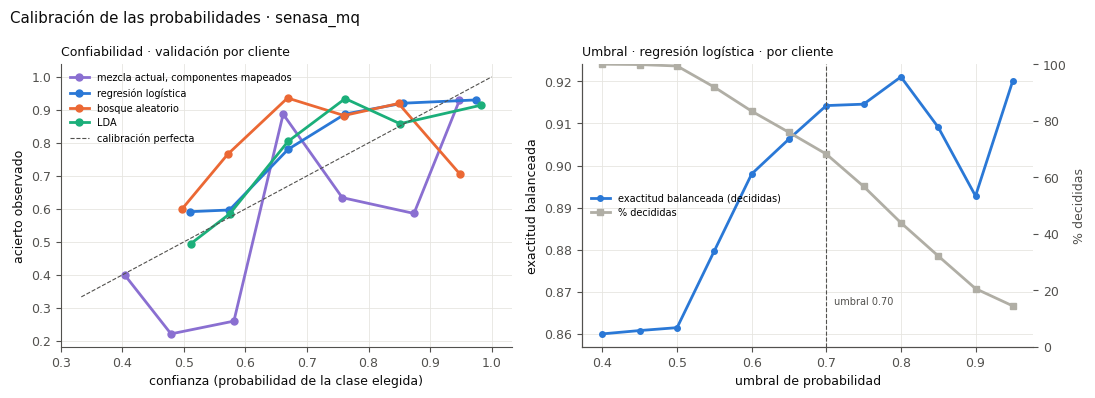

umbral,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95
% decididas,99.938,99.813,99.313,91.818,83.323,75.828,68.145,56.715,43.848,32.105,20.550,14.428
exactitud balanceada,0.860,0.861,0.861,0.880,0.898,0.906,0.914,0.915,0.921,0.909,0.893,0.920


In [13]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.0))
ax = axs[0]
bins = np.linspace(1 / 3, 1, 8)
estilo = {"(b) mezcla actual, componentes mapeados": "#8a6fd1", "(c) regresión logística": "#2a78d6", "(c) bosque aleatorio": "#eb6834", "(c) LDA": "#1baf7a"}
for n_, col_ in estilo.items():
    P = OOF["por cliente"][n_]; conf = P.max(axis=1); ok = predecir(P) == y
    b = np.clip(np.digitize(conf, bins) - 1, 0, len(bins) - 2)
    xs = [conf[b == i].mean() for i in range(len(bins) - 1) if (b == i).sum() >= 10]
    ys = [ok[b == i].mean() for i in range(len(bins) - 1) if (b == i).sum() >= 10]
    ax.plot(xs, ys, marker="o", ms=5, lw=2, color=col_, label=n_.replace("(b) ", "").replace("(c) ", ""))
ax.plot([1 / 3, 1], [1 / 3, 1], color=TINTA2, lw=0.8, ls="--", label="calibración perfecta")
ax.set_xlabel("confianza (probabilidad de la clase elegida)"); ax.set_ylabel("acierto observado")
ax.set_title("Confiabilidad · validación por cliente", loc="left", fontsize=9, color=TINTA); ax.legend(fontsize=7, frameon=False, loc="upper left")
ax = axs[1]
umbrales = np.round(np.arange(0.40, 0.96, 0.05), 2); P = OOF["por cliente"][mejor]; conf = P.max(axis=1); pred = predecir(P)
curva = pd.DataFrame([{"umbral": u, "% decididas": 100 * (conf >= u).mean(),
                       "exactitud balanceada": balanced_accuracy_score(y[conf >= u], pred[conf >= u]) if (conf >= u).sum() > 10 else np.nan}
                      for u in umbrales]).set_index("umbral")
ax.plot(curva.index, curva["exactitud balanceada"], marker="o", ms=4, lw=2, color="#2a78d6", label="exactitud balanceada (decididas)")
ax2 = ax.twinx(); ax2.set_ylim(0, 100); ax2.set_ylabel("% decididas", color=TINTA2); ax2.spines["top"].set_visible(False); ax2.grid(False)
ax2.plot(curva.index, curva["% decididas"], marker="s", ms=4, lw=2, color="#b0aea5", label="% decididas")
ax.axvline(UMBRAL, color=TINTA2, lw=0.8, ls="--"); ax.text(UMBRAL + 0.01, ax.get_ylim()[0] + 0.01, f"umbral {UMBRAL:.2f}", fontsize=7, color=TINTA2)
ax.set_xlabel("umbral de probabilidad"); ax.set_ylabel("exactitud balanceada")
ax.set_title(f"Umbral · {mejor.replace('(c) ', '')} · por cliente", loc="left", fontsize=9, color=TINTA)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=7, frameon=False, loc="center left")
fig.suptitle(f"Calibración de las probabilidades · {v}", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); guardar(fig, f"calibracion_{v}.png"); plt.show()
display(curva.round(3).T)

### 2.5 · ¿Ayuda la actividad de agua (Aw)?
Solo una parte de las etiquetadas tiene Aw, casi todas familiar o repostero, así que se mira **repostero contra
familiar** con regresión logística, con y sin Aw, sobre esas mismas muestras. No se imputa: con tan pocas muestras con
valor, imputar la mediana inventaría casi toda la columna.

In [14]:
con_aw = d[lab & d["aw"].notna() & d["subtipo"].isin(["FAMILIAR", "REPOSTERO"])]
print(f"Con Aw: {d['aw'].notna().sum()} muestras DDL ({d.loc[lab, 'aw'].notna().sum()} etiquetadas, {d.loc[~lab, 'aw'].notna().sum()} sin subtipo); "
      f"familiar/repostero con Aw: {len(con_aw)}, por cliente: {con_aw['cliente'].value_counts().to_dict()}")
yy = (con_aw["subtipo"] == "REPOSTERO").astype(int).to_numpy(); gg = con_aw["cliente"].to_numpy()
fab = lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
filas = []
for nombre_, cols_ in [("4 análisis", COLUMNAS), ("4 análisis + Aw", COLUMNAS + ["aw"]), ("solo Aw", ["aw"])]:
    Xa = con_aw[cols_].to_numpy(); f_ = {"variables": nombre_}
    for val, cv in [("estratificada", CV_ESTR), ("por cliente", CV_CLI)]:
        pr = np.zeros(len(yy))
        for tr, te in (cv.split(Xa, yy, gg) if val == "por cliente" else cv.split(Xa, yy)):
            if len(np.unique(yy[tr])) < 2:
                pr[te] = yy[tr][0]; continue
            pr[te] = fab().fit(Xa[tr], yy[tr]).predict(Xa[te])
        f_[f"exactitud balanceada ({val})"] = round(balanced_accuracy_score(yy, pr), 3)
    filas.append(f_)
display(pd.DataFrame(filas).set_index("variables"))
display(con_aw.groupby(["cliente", "subtipo"])["aw"].agg(["count", "median"]).round(3))

Con Aw: 321 muestras DDL (311 etiquetadas, 10 sin subtipo); familiar/repostero con Aw: 309, por cliente: {'IND-51': 165, 'IND-11': 116, 'IND-52': 12, 'IND-71': 6, 'IND-93': 6, 'IND-41': 1, 'IND-05': 1, 'IND-107': 1, 'IND-105': 1}


,exactitud balanceada (estratificada),exactitud balanceada (por cliente)
variables,,
4 análisis,0.862,0.600
4 análisis + Aw,0.882,0.772
solo Aw,0.884,0.887


count  median
cliente subtipo                 
IND-05  REPOSTERO      1   0.751
IND-105 REPOSTERO      1   0.741
IND-107 REPOSTERO      1   0.779
IND-11  FAMILIAR      75   0.837
        REPOSTERO     41   0.839
IND-41  REPOSTERO      1   0.751
IND-51  FAMILIAR       1   0.824
        REPOSTERO    164   0.802
IND-52  FAMILIAR      10   0.828
        REPOSTERO      2   0.790
IND-71  REPOSTERO      6   0.750
IND-93  FAMILIAR       3   0.843
        REPOSTERO      3   0.812

### 2.6 · ¿Las sin subtipo se parecen a algún subtipo?
Medianas de las sin subtipo (todas y las de IND-38) junto a las de cada subtipo. Novedad: (i) distancia de **Mahalanobis
robusta** (MCD) a cada clase; una muestra es novedad si queda más allá del percentil {PCT} de los propios miembros en
**las tres** clases; (ii) **LOF** en modo novedad (30 vecinos, ajustado con las etiquetadas estandarizadas), con el corte en el percentil 1 del
puntaje de las etiquetadas (calculado fuera de pliegue); el corte por defecto de LOF daba entre 8 y 31 % de falsas
alarmas. Se marca como novedad si lo dice cualquiera de los dos. Como referencia, la tasa de falsas alarmas en las etiquetadas (con LOF en
validación cruzada, para no evaluarlo sobre sus propios datos de ajuste).

In [15]:
X = d[COLUMNAS].to_numpy(); Xl = X[lab]
grupo = np.where(lab, d["subtipo"].fillna(""), np.where(d["cliente"] == CLIENTE_FOCO, "sin subtipo · IND-38", "sin subtipo · otros"))
med = pd.DataFrame(X, columns=COLUMNAS).groupby(grupo).median().round(2)
med.insert(0, "muestras", pd.Series(grupo).value_counts())
display(med.loc[CLASES + ["sin subtipo · IND-38", "sin subtipo · otros"]])

D, U, nov_maha = mahalanobis_por_clase(Xl, y, X)
esc = StandardScaler().fit(Xl)
lof = LocalOutlierFactor(n_neighbors=30, novelty=True).fit(esc.transform(Xl))
puntaje = lof.score_samples(esc.transform(X))     # más bajo = más raro
oof_lof = np.zeros(lab.sum())                     # LOF en las etiquetadas, fuera de pliegue (no sobre sus datos de ajuste)
for tr, te in CV_ESTR.split(Xl, y):
    e_ = StandardScaler().fit(Xl[tr]); oof_lof[te] = LocalOutlierFactor(n_neighbors=30, novelty=True).fit(e_.transform(Xl[tr])).score_samples(e_.transform(Xl[te]))
corte_lof = np.percentile(oof_lof, 100 - PCT_NOVEDAD)   # calibrado: ~1 % de falsas alarmas en las etiquetadas
puntaje[lab] = oof_lof
nov_lof = puntaje < corte_lof
print(f"Corte de LOF (percentil {100 - PCT_NOVEDAD} del puntaje fuera de pliegue de las etiquetadas): {corte_lof:.2f}")
novedad = nov_maha | nov_lof
d["novedad"] = novedad; d["clase_mas_cercana"] = D.div(U).idxmin(axis=1)
print("Umbral de Mahalanobis por clase (percentil 99 de sus miembros):", U.round(2).to_dict())
fr = pd.DataFrame({"Mahalanobis": nov_maha, "LOF": nov_lof, "cualquiera": novedad}).groupby(grupo).mean().mul(100).round(1)
fr.insert(0, "muestras", pd.Series(grupo).value_counts())
print("% marcadas como novedad por grupo (en las etiquetadas = falsas alarmas):"); display(fr)
print("Sin subtipo: clase más cercana (Mahalanobis relativa al umbral) × novedad:")
display(pd.crosstab([pd.Series(grupo[~lab], name="grupo"), d.loc[~lab, "clase_mas_cercana"].rename("más cercana")], d.loc[~lab, "novedad"].rename("novedad")))

,muestras,humedad,grasa,proteinas,cenizas
FAMILIAR,789,28.75,6.73,5.85,1.36
REPOSTERO,637,26.64,6.81,6.63,1.50
HELADERO,175,21.86,6.93,6.76,2.58
sin subtipo · IND-38,326,29.35,8.18,7.97,1.85
sin subtipo · otros,299,28.38,6.72,6.19,1.52


Corte de LOF (percentil 1 del puntaje fuera de pliegue de las etiquetadas): -2.55
Umbral de Mahalanobis por clase (percentil 99 de sus miembros): {'FAMILIAR': 259.53, 'REPOSTERO': 66.1, 'HELADERO': 213.17}
% marcadas como novedad por grupo (en las etiquetadas = falsas alarmas):


,muestras,Mahalanobis,LOF,cualquiera
FAMILIAR,789,1.0,0.6,1.6
HELADERO,175,0.0,4.6,4.6
REPOSTERO,637,0.0,0.5,0.5
sin subtipo · IND-38,326,0.0,2.1,2.1
sin subtipo · otros,299,0.0,1.7,1.7


Sin subtipo: clase más cercana (Mahalanobis relativa al umbral) × novedad:


novedad                           False  True 
grupo                más cercana              
sin subtipo · IND-38 FAMILIAR       150      4
                     REPOSTERO       53      2
sin subtipo · otros  FAMILIAR       111      1
                     REPOSTERO       45      0

### 2.7 · Subtipo propuesto
El mejor método con probabilidades según la validación por cliente (entre los que quedan a menos de 0,01 de la mejor
exactitud balanceada, el de menor Brier) se reajusta con **todas** las etiquetadas y se aplica
a las sin subtipo. Regla de decisión explícita: si la probabilidad de la clase elegida es menor que **{UMBRAL}**, o si
la muestra es novedad, queda **sin decidir**. Las etiquetadas llevan su predicción **fuera de pliegue por cliente**
(honesta), para poder comparar con el subtipo real. Se compara además con la regla y con la mezcla actual.

In [16]:
modelo_final = MET[mejor](idx)
P_todo = modelo_final(np.arange(len(d)))
P_todo[lab] = OOF["por cliente"][mejor]
prob = P_todo.max(axis=1); pred = predecir(P_todo)
decidido = (prob >= UMBRAL) & ~novedad
d["subtipo_propuesto"] = np.where(decidido, pred, "sin decidir"); d["prob"] = prob
for k, col_ in zip(CLASES, ["p_familiar", "p_repostero", "p_heladero"]):
    d[col_] = P_todo[:, CLASES.index(k)]

sin = d[~lab]
orden = CLASES + ["sin decidir"]
conteo = pd.DataFrame({"todas las sin subtipo": sin["subtipo_propuesto"].value_counts(),
                       f"{CLIENTE_FOCO} sin subtipo": sin.loc[sin["cliente"] == CLIENTE_FOCO, "subtipo_propuesto"].value_counts(),
                       "otros clientes sin subtipo": sin.loc[sin["cliente"] != CLIENTE_FOCO, "subtipo_propuesto"].value_counts()}).reindex(orden).fillna(0).astype(int)
conteo.loc["total"] = conteo.sum(); display(conteo)
print("Por qué quedan sin decidir (sin subtipo):",
      {"novedad": int(sin["novedad"].sum()), f"prob < {UMBRAL}": int(((sin["prob"] < UMBRAL) & ~sin["novedad"]).sum())})
print("Clase más probable de las sin decidir, sin mirar el umbral:", pd.Series(pred[~lab][~decidido[~lab]]).value_counts().to_dict())
regla_sin = predecir(MET["(a) regla"](idx)(np.flatnonzero(~lab)))
print("Sin subtipo: propuesto (mejor método) × regla:"); display(pd.crosstab(sin["subtipo_propuesto"].rename("propuesto"), pd.Series(regla_sin, index=sin.index, name="regla")))
print("Sin subtipo: propuesto × subtag actual:"); display(pd.crosstab(sin["subtipo_propuesto"].rename("propuesto"), sin["subtag"]))
print("Etiquetadas (fuera de pliegue por cliente), solo las decididas: propuesto × real")
display(pd.crosstab(d.loc[lab, "subtipo"].rename("real"), d.loc[lab, "subtipo_propuesto"].rename("propuesto")))
dl = d[lab & decidido]
print(f"Etiquetadas decididas: {len(dl)} de {lab.sum()} · exactitud balanceada {balanced_accuracy_score(dl['subtipo'], dl['subtipo_propuesto']):.3f}")

out = d[["Identificador", "cliente", "origen"] + COLUMNAS + ["aw", "subtag", "componente", "subtipo", "subtipo_propuesto", "prob",
        "p_familiar", "p_repostero", "p_heladero", "novedad", "clase_mas_cercana"]].copy()
out = out.rename(columns={"subtipo": "subtipo_real", "prob": "probabilidad"})
out.insert(out.columns.get_loc("subtipo_propuesto") + 1, "metodo", mejor.replace("(c) ", "") + (" (fuera de pliegue por cliente)"))
out.loc[out["subtipo_real"].isna(), "metodo"] = mejor.replace("(c) ", "") + " (ajustado con todas las etiquetadas)"
out["decidido"] = np.where(decidido, "sí", "no"); out["umbral"] = UMBRAL
out = out.round({c_: 3 for c_ in COLUMNAS + ["aw", "probabilidad", "p_familiar", "p_repostero", "p_heladero"]})
out.to_csv(SALIDA / f"subtipo_propuesto_{v}.csv", index=False, encoding="utf-8-sig")
print("CSV:", (SALIDA / f"subtipo_propuesto_{v}.csv").relative_to(R.RAIZ), out.shape)
RES[v] = dict(ba=ba, tabla=tabla, mejor=mejor, conteo=conteo, por_cliente=por_cliente, fr=fr, d=d)

,todas las sin subtipo,IND-38 sin subtipo,otros clientes sin subtipo
subtipo_propuesto,,,
FAMILIAR,246,128,118
REPOSTERO,147,94,53
HELADERO,8,2,6
sin decidir,224,102,122
total,625,326,299


Por qué quedan sin decidir (sin subtipo): {'novedad': 12, 'prob < 0.7': 212}
Clase más probable de las sin decidir, sin mirar el umbral: {'FAMILIAR': 126, 'REPOSTERO': 96, 'HELADERO': 2}
Sin subtipo: propuesto (mejor método) × regla:


regla,FAMILIAR,HELADERO,REPOSTERO
propuesto,,,
FAMILIAR,243,0,3
HELADERO,3,2,3
REPOSTERO,94,3,50
sin decidir,197,1,26


Sin subtipo: propuesto × subtag actual:


subtag,DDL,DDL_FAMILIAR
propuesto,,
FAMILIAR,126,120
HELADERO,8,0
REPOSTERO,135,12
sin decidir,176,48


Etiquetadas (fuera de pliegue por cliente), solo las decididas: propuesto × real


propuesto,FAMILIAR,HELADERO,REPOSTERO,sin decidir
real,,,,
FAMILIAR,546,2,39,202
HELADERO,0,154,4,17
REPOSTERO,50,4,277,306


Etiquetadas decididas: 1076 de 1601 · exactitud balanceada 0.914
CSV: resultados\prueba_subtipo_ddl\subtipo_propuesto_senasa_mq.csv (2226, 21)


### 2.8 · Gráfico: dónde caen las sin subtipo
Fondo: las etiquetadas por subtipo. Encima, las sin subtipo con el subtipo propuesto (relleno) o sin decidir (gris);
las novedades, con una cruz. Los paneles de abajo son solo IND-38.

PNG: resultados\prueba_subtipo_ddl\sin_subtipo_senasa_mq.png


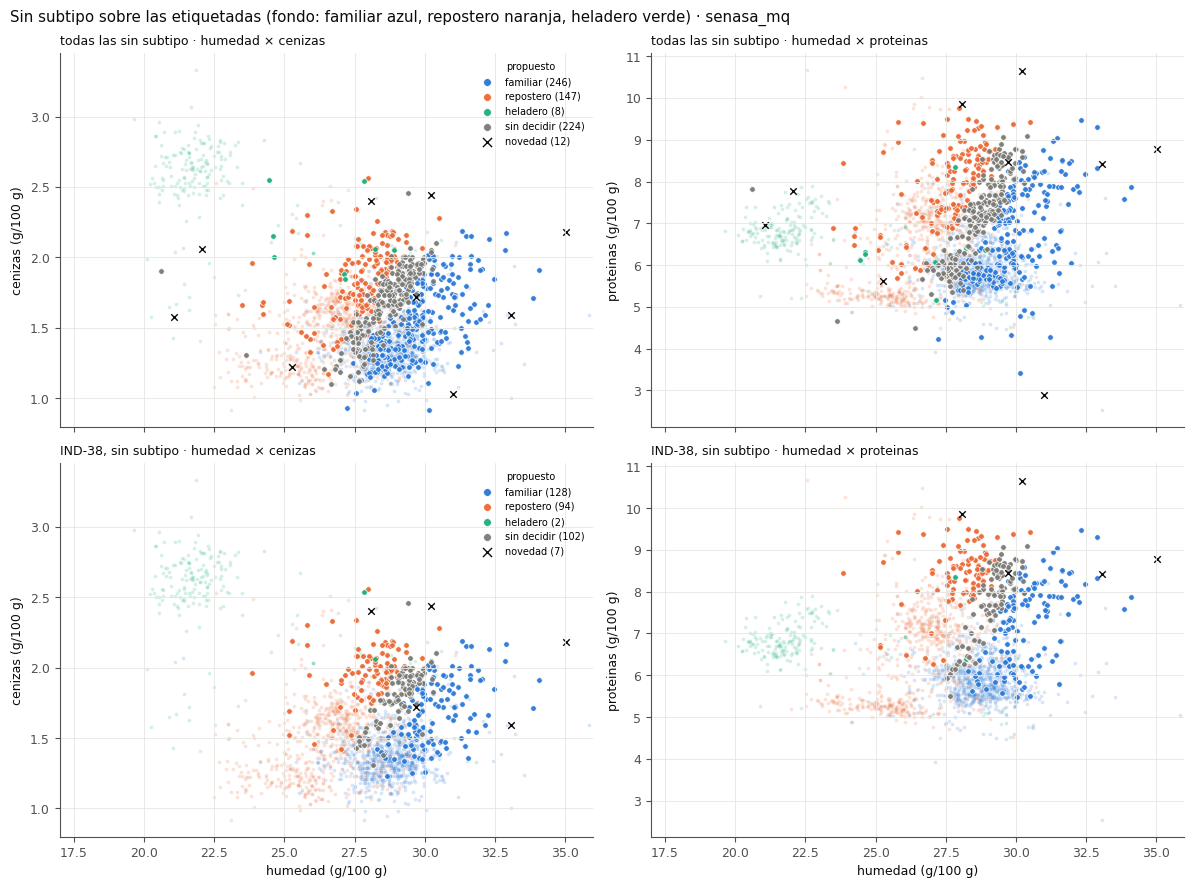

PNG: resultados\prueba_subtipo_ddl\confusion_senasa_mq.png


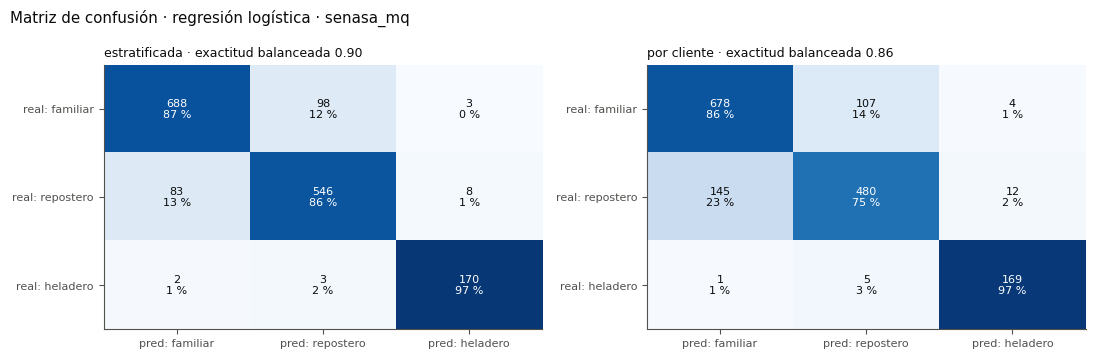

In [17]:
fig, axs = plt.subplots(2, 2, figsize=(12, 9), sharex=True)
for fila_, sel_, rot_ in [(0, ~lab, "todas las sin subtipo"), (1, ~lab & (d["cliente"] == CLIENTE_FOCO).to_numpy(), f"{CLIENTE_FOCO}, sin subtipo")]:
    for ax, yv in zip(axs[fila_], ["cenizas", "proteinas"]):
        for k in CLASES:
            q = d[lab & (d["subtipo"] == k).to_numpy()]
            ax.scatter(q["humedad"], q[yv], s=7, color=COLOR[k], alpha=0.18, lw=0)
        s_ = d[sel_]
        for k in CLASES + ["sin decidir"]:
            q = s_[(s_["subtipo_propuesto"] == k) & ~s_["novedad"]]
            ax.scatter(q["humedad"], q[yv], s=16, color=COLOR.get(k, "#7a7974"), edgecolors="white", lw=0.5, alpha=0.95,
                       label=f"{k.lower()} ({(s_['subtipo_propuesto'] == k).sum()})")
        q = s_[s_["novedad"]]
        ax.scatter(q["humedad"], q[yv], s=22, marker="x", color=TINTA, lw=1, label=f"novedad ({len(q)})")
        ax.set_xlim(17, 36); ax.set_ylabel(f"{yv} (g/100 g)")
        ax.set_title(f"{rot_} · humedad × {yv}", loc="left", fontsize=9, color=TINTA)
        if fila_ == 1:
            ax.set_xlabel("humedad (g/100 g)")
    axs[fila_][0].legend(fontsize=7, frameon=False, markerscale=1.4, loc="upper right", title="propuesto", title_fontsize=7)
fig.suptitle(f"Sin subtipo sobre las etiquetadas (fondo: familiar azul, repostero naranja, heladero verde) · {v}", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); guardar(fig, f"sin_subtipo_{v}.png"); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, val in zip(axs, ["estratificada", "por cliente"]):
    m_ = matriz(y, OOF[val][mejor]); filas_ = m_.div(m_.sum(axis=1), axis=0)
    ax.imshow(filas_.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(m_.shape[0]):
        for j in range(m_.shape[1]):
            ax.text(j, i, f"{m_.iat[i, j]}\n{100 * filas_.iat[i, j]:.0f} %", ha="center", va="center", fontsize=8,
                    color="white" if filas_.iat[i, j] > 0.55 else TINTA)
    ax.set_xticks(range(m_.shape[1])); ax.set_xticklabels(m_.columns, fontsize=8); ax.set_yticks(range(3)); ax.set_yticklabels(m_.index, fontsize=8)
    ax.grid(False); ax.set_title(f"{val} · exactitud balanceada {balanced_accuracy_score(y, predecir(OOF[val][mejor])):.2f}", loc="left", fontsize=9, color=TINTA)
fig.suptitle(f"Matriz de confusión · {mejor.replace('(c) ', '')} · {v}", x=0.01, ha="left", color=TINTA)
fig.tight_layout(); guardar(fig, f"confusion_{v}.png"); plt.show()

## 3 · Las dos versiones, lado a lado

senasa · mejor método por cliente: (c) regresión logística


validación,estratificada,por cliente
método,,
(a) regla,0.835,0.835
(b) mezcla actual (mapeo de proponer_subtag),0.525,0.525
"(b) mezcla actual, componentes mapeados",0.822,0.746
(c) LDA,0.866,0.830
(c) bosque aleatorio,0.906,0.863
(c) regresión logística,0.902,0.862


senasa_mq · mejor método por cliente: (c) regresión logística


validación,estratificada,por cliente
método,,
(a) regla,0.832,0.832
(b) mezcla actual (mapeo de proponer_subtag),0.524,0.524
"(b) mezcla actual, componentes mapeados",0.852,0.764
(c) LDA,0.868,0.826
(c) bosque aleatorio,0.912,0.860
(c) regresión logística,0.900,0.860


senasa                                                           senasa_mq                                              
                  todas las sin subtipo IND-38 sin subtipo otros clientes sin subtipo todas las sin subtipo IND-38 sin subtipo otros clientes sin subtipo
subtipo_propuesto                                                                                                                                        
FAMILIAR                            246                136                        110                   246                128                        118
REPOSTERO                           130                 89                         41                   147                 94                         53
HELADERO                              7                  2                          5                     8                  2                          6
sin decidir                         212                 99                        113                   224                102                        122
total                               595                326                        269                   625                326                        299

PNG: resultados\prueba_subtipo_ddl\metodos_senasa.png


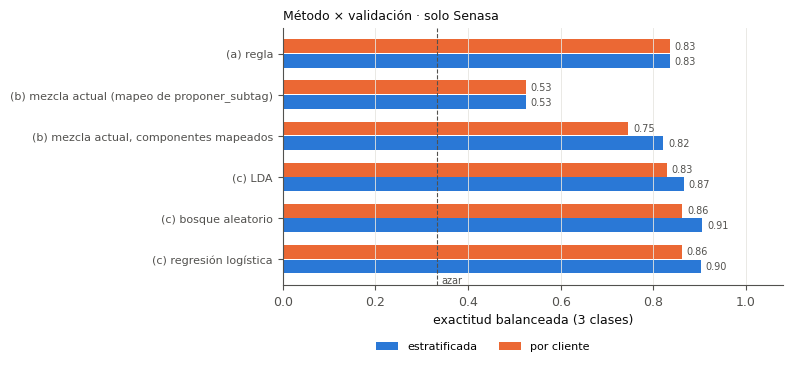

In [18]:
for v_, r_ in RES.items():
    print(f"{v_} · mejor método por cliente: {r_['mejor']}"); display(r_["ba"])
display(pd.concat({v_: r_["conteo"] for v_, r_ in RES.items()}, axis=1))
fig, ax = plt.subplots(figsize=(8, 3.8))
b_ = RES["senasa"]["ba"]; ypos = np.arange(len(b_))
ax.barh(ypos + 0.18, b_["estratificada"], height=0.34, color="#2a78d6", label="estratificada")
ax.barh(ypos - 0.18, b_["por cliente"], height=0.34, color="#eb6834", label="por cliente")
for i, (a_, c_) in enumerate(zip(b_["estratificada"], b_["por cliente"])):
    ax.text(a_ + 0.01, i + 0.18, f"{a_:.2f}", va="center", fontsize=7, color=TINTA2); ax.text(c_ + 0.01, i - 0.18, f"{c_:.2f}", va="center", fontsize=7, color=TINTA2)
ax.axvline(1 / 3, color=TINTA2, lw=0.8, ls="--"); ax.text(1 / 3 + 0.01, len(b_) - 0.4, "azar", fontsize=7, color=TINTA2)
ax.set_yticks(ypos); ax.set_yticklabels(b_.index, fontsize=8); ax.invert_yaxis(); ax.set_xlim(0, 1.08); ax.grid(axis="y", visible=False)
ax.set_xlabel("exactitud balanceada (3 clases)"); ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.4, -0.18))
ax.set_title("Método × validación · solo Senasa", loc="left", fontsize=9, color=TINTA)
fig.tight_layout(); guardar(fig, "metodos_senasa.png"); plt.show()

## 4 · Veredicto
### ¿Qué método conviene para el notebook completo?

**La regresión logística multinomial** (peso de clase balanceado) sobre humedad, grasa, proteínas y cenizas, con un
umbral de probabilidad de **0,70** y la marca de novedad. Exactitud balanceada (3 clases):

| método | estratificada | por cliente |
|---|---|---|
| (a) regla (heladero: cenizas > 2,0 y humedad ≤ 26; repostero: humedad ≤ 27,6 y cenizas ≤ 2,0) | 0,84 | 0,84 (optimista: los umbrales se eligieron con todas las etiquetas) |
| (b) mezcla actual, mapeo de `proponer_subtag` | 0,53 | 0,53 (nunca propone repostero; el 49 % queda como «DDL») |
| (b) mezcla actual, componentes mapeados con las etiquetas | 0,82 | 0,75 |
| (c) regresión logística | 0,90 | **0,86** |
| (c) bosque aleatorio chico | 0,91 | 0,86 |
| (c) LDA | 0,87 | 0,83 |

(Solo Senasa; en Senasa + MQ los números son casi iguales: logística 0,90 / 0,86 y bosque 0,91 / 0,86; la población de Senasa + MQ sale ahora de `MQ encolumnado.xlsx`, sin las MO.)

- El bosque y la logística empatan por cliente, pero la logística está **mejor calibrada** (Brier 0,26 contra 0,30; ECE
  0,08 contra 0,17), y las probabilidades se usan con un umbral. Además, el bosque **falla en IND-38**: acierta 2 de 17
  etiquetadas sin haber visto al cliente (2 de 19 en Senasa + MQ), mientras que la logística acierta todas.
  El bosque corta en valores absolutos y no extrapola a una receta con más proteína.
- La mezcla no sirve para asignar el subtipo. Con su mapeo actual no tiene repostero. Con los componentes mapeados cae a
  0,75 en clientes no vistos y queda mal calibrada.
- Con umbral 0,70, la logística decide alrededor del 70 % de las etiquetadas (validación por cliente) con exactitud
  balanceada 0,91. Si se sube el umbral, casi no mejora y se pierden muchas decididas.
- El error que queda es **repostero ↔ familiar** (22 % de los reposteros van a familiar en clientes no vistos). El heladero
  sale bien con la logística (95 % en clientes no vistos); la regla acierta el 84 %.

### Subtipo propuesto para las sin subtipo (logística, umbral 0,70, sin novedad)

| | familiar | repostero | heladero | sin decidir | total |
|---|---|---|---|---|---|
| solo Senasa, todas | 246 | 130 | 7 | 212 | 595 |
| solo Senasa, IND-38 | 136 | 89 | 2 | 99 | 326 |
| Senasa + MQ, todas | 246 | 147 | 8 | 224 | 625 |
| Senasa + MQ, IND-38 | 128 | 94 | 2 | 102 | 326 |

Casi todas las «sin decidir» lo son por probabilidad baja: solo 19 (12 en Senasa + MQ) son novedad.

### ¿Se puede confiar en las asignaciones de IND-38?

**Solo en parte: el familiar sí, el repostero con cautela.**

- IND-38 tiene **17 etiquetadas** (13 reposteros y 4 familiares; 19 en Senasa + MQ). La logística las acierta todas sin
  haber visto al cliente. Pero son casos fáciles: los reposteros tienen humedad de 25 a 27,6 y los familiares, más de
  30. Las sin subtipo de IND-38 caen **en el medio** (mediana de humedad 29,4).
- IND-38 es **otra receta**: tiene más proteína (mediana 8,0) y más grasa (8,2) que cualquier subtipo etiquetado
  (proteína: familiar 5,8, repostero 6,6, heladero 6,7). No queda fuera de las zonas: la novedad marca solo el 4 % (2 % en Senasa + MQ),
  porque las clases son anchas. Pero queda en un borde donde el modelo **extrapola**.
- Los reposteros propuestos de IND-38 tienen una humedad mediana de 28,3, más alta que la del repostero típico (26,6).
  Los empuja el coeficiente de proteína, que se aprendió sobre todo con IND-51. Los familiares propuestos (humedad
  mediana 30,1) son más creíbles.
- La validación por cliente fuera de IND-51 es floja: en IND-11 la logística acierta el 56 % y en IND-107, el 64 %. La
  señal repostero / familiar depende del cliente.

### ¿Qué dato extra mejoraría la separación?

- **Etiquetar unas 30 a 50 muestras de IND-38** en la zona de humedad 27,5 a 30. Es lo que más rinde: hoy no hay
  ninguna etiquetada en esa zona.
- **Actividad de agua (Aw).** En las 309 etiquetadas familiar / repostero que la tienen, por cliente: 0,60 con los cuatro
  análisis, 0,77 si se agrega la Aw y 0,89 con solo la Aw. Pero esa ganancia está **confundida con el cliente**: casi
  todos los reposteros con Aw son de IND-51 y casi todos los familiares, de IND-11. Dentro de IND-11, la Aw del
  repostero es igual a la del familiar (0,839 contra 0,837). Además, solo 10 de las 595 sin subtipo tienen Aw, así que
  hoy no sirve para predecir. Conviene medirla siempre, pero no es la solución por sí sola.
- Algo de **textura o consistencia** (viscosidad, `desc_consistencia`, hoy vacío) y los **sólidos solubles o azúcares**:
  el repostero se define por su firmeza, no por la composición centesimal.

### Dudas

- La etiqueta «repostero» la define sobre todo IND-51 (459 de 620). Cualquier modelo aprende el repostero de IND-51.
- El alfajorero (27 muestras) ya venía como repostero en el subtipo de referencia, así que la decisión no cambia
  ninguna etiqueta.
- El umbral 0,70 y el percentil 99 de la novedad son decisiones; el CSV guarda las tres probabilidades para cambiarlos sin
  reentrenar.